# Skill Extraction Validation & Descriptive Analysis

This notebook builds on the cleaned and combined job-market dataset produced in the data collection phase.

Our goals are to:

- validate and refine the extracted technical skills, especially ambiguous terms such as **Go** and **R**
- measure overall skill demand across the full dataset
- compare skill demand across **data sources, seniority levels, and work models**
- identify common skill combinations
- compute normalized co-occurrence strength using **Jaccard similarity**
- prepare clean outputs for the later **salary-modeling** and **graph-analysis** phases

The main input for this notebook is:

- `Datasets/combined_data.csv`

At the end of the notebook, we export the following analysis files:

- `Datasets/skill_frequency_stats.csv` — overall skill frequency and demand percentage
- `Datasets/skill_by_source.csv` — skill demand by data source
- `Datasets/skill_by_seniority.csv` — skill demand by seniority level
- `Datasets/skill_by_workmode.csv` — skill demand by work model
- `Datasets/skill_pair_stats.csv` — skill co-occurrence counts and Jaccard similarity
- `Datasets/job_skills_clean.csv` — cleaned job-to-skill mapping for downstream analysis

These outputs will be used as inputs for the next phases of the project, particularly salary regression and skill-network analysis.

In [24]:
import pandas as pd
import numpy as np
import ast
import matplotlib.pyplot as plt
import re

from itertools import combinations
from collections import Counter

# Load Silvia's final combined dataset
df = pd.read_csv("Datasets/combined_data.csv")

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

# Inspect the core strcuture

print(df["source"].value_counts())
print(df["level"].value_counts())
print(df["work_mode"].value_counts())

print("\nMissing values:")
print(df.isna().sum().sort_values(ascending=False))

Dataset shape: (6869, 18)

Columns:
['Unnamed: 0', 'source', 'job_id', 'title', 'company', 'location', 'categories', 'level', 'pub_date', 'currency', 'annual_salary', 'skills', 'description', 'url', 'work_mode', 'row_id', 'loose_key', 'job_uid']


,Unnamed: 0,source,job_id,title,company,location,categories,level,pub_date,currency,annual_salary,skills,description,url,work_mode,row_id,loose_key,job_uid
0,0,muse,21666246.0,"Machine Learning Engineer, AI Inference Soluti...",General Motors,sunnyvale; ca,['data and analytics'],Entry,2026-10-07 21:51:43+00:00,USD,135050.0,"['python', 'r', 'c++', 'pytorch', 'airflow', '...",Description General Motors is a global leader ...,https://www.themuse.com/jobs/generalmotors/mac...,Hybrid,0,general motors|machine learning engineer ai in...,0
1,1,muse,16045945.0,Machine Learning Engineer - CV/NLP/Multimodal ...,TikTok,san jose; ca,['data and analytics'],Entry,2025-08-03 04:35:29+00:00,USD,152928.5,"['computer vision', 'nlp']",Responsibilities The algorithm team is respon...,https://www.themuse.com/jobs/tiktok/machine-le...,Onsite,1,tiktok|machine learning engineer cv nlp multim...,1
2,2,muse,21744742.0,Junior Cyber Analyst,Leidos,fort meade; md,['data and analytics'],Entry,2026-08-29 22:44:09+00:00,USD,81212.5,['typescript'],Description The Cyber & Analytics Business...,https://www.themuse.com/jobs/leidos/junior-cyb...,Onsite,2,leidos|junior cyber analyst|Entry,2
3,3,muse,22030232.0,Machine Learning Engineer Graduate (Ads Signal...,TikTok,san jose; ca,['data and analytics'],Entry,2026-08-04 20:22:16+00:00,USD,192000.0,"['python', 'c++', 'java', 'go', 'pytorch', 'te...",Responsibilities The Signal & Measurement tea...,https://www.themuse.com/jobs/tiktok/machine-le...,Onsite,3,tiktok|machine learning engineer graduate 2027...,3
4,4,muse,19307581.0,Solutions Architect,Enterprise Mobility,st. louis; mo,['data and analytics'],Entry,2025-06-24 12:37:47+00:00,USD,149500.0,['aws'],Overview The St. Louis Support Services Divisi...,https://www.themuse.com/jobs/enterprisemobilit...,Hybrid,4,enterprise mobility|solutions architect|Entry,4


source
himalayas    3469
muse         3400
Name: count, dtype: int64
level
Senior    4146
Mid       2121
Lead+      303
Entry      289
Intern      10
Name: count, dtype: int64
work_mode
Remote    3625
Onsite    2911
Hybrid     333
Name: count, dtype: int64

Missing values:
job_id           3469
url              3469
location            4
currency            1
annual_salary       0
loose_key           0
row_id              0
work_mode           0
description         0
skills              0
Unnamed: 0          0
source              0
pub_date            0
level               0
categories          0
company             0
title               0
job_uid             0
dtype: int64


In [26]:
# Parsing the Skills field

def parse_skills(value):
    if pd.isna(value):
        return []

    if isinstance(value, list):
        return value

    try:
        parsed = ast.literal_eval(value)

        if isinstance(parsed, list):
            return [
                str(skill).strip()
                for skill in parsed
                if str(skill).strip()
            ]

    except (ValueError, SyntaxError):
        pass

    return []

df["skills_list"] = df["skills"].apply(parse_skills)
df["skill_count"] = df["skills_list"].apply(len)

df[["title", "skills", "skills_list"]].head(10)

,title,skills,skills_list
0,"Machine Learning Engineer, AI Inference Soluti...","['python', 'r', 'c++', 'pytorch', 'airflow', '...","[python, r, c++, pytorch, airflow, llm / genai..."
1,Machine Learning Engineer - CV/NLP/Multimodal ...,"['computer vision', 'nlp']","[computer vision, nlp]"
2,Junior Cyber Analyst,['typescript'],[typescript]
3,Machine Learning Engineer Graduate (Ads Signal...,"['python', 'c++', 'java', 'go', 'pytorch', 'te...","[python, c++, java, go, pytorch, tensorflow, a..."
4,Solutions Architect,['aws'],[aws]
5,"AI Engineer, Supercomputing, Special Programs ...","['python', 'go', 'kubernetes', 'terraform', 'l...","[python, go, kubernetes, terraform, linux, git..."
6,Sourcing Specialist (Starship),"['sql', 'power bi']","[sql, power bi]"
7,Production Coordinator (Falcon),"['sql', 'tableau']","[sql, tableau]"
8,"Propulsion Engineer, Avionics Manufacturing (R...",['python'],[python]
9,Gateway Fleet Specialist,['sql'],[sql]


In [27]:
# Document the analytical sample

total_jobs = len(df)
jobs_with_skills = (df["skill_count"] > 0).sum()

print("Total jobs:", total_jobs)
print("Jobs with at least one skill:", jobs_with_skills)
print("Coverage:", jobs_with_skills / total_jobs * 100)

Total jobs: 6869
Jobs with at least one skill: 6869
Coverage: 100.0


##### The final combined dataset was already filtered upstream to retain jobs with detected technical skills. Therefore, 100% coverage refers to the analytical sample, not to perfect extraction accuracy.

### <b>Initial skill-frequency sanity check</b>

In [28]:
# Calculating first ranking

skills_exploded = (
    df[["job_uid", "skills_list"]]
    .explode("skills_list")
    .dropna()
    .rename(columns={"skills_list": "skill"})
)

initial_skill_frequency = (
    skills_exploded
    .groupby("skill")
    .agg(job_count=("job_uid", "nunique"))
    .reset_index()
)

initial_skill_frequency["demand_pct"] = (
    initial_skill_frequency["job_count"]
    / df["job_uid"].nunique()
    * 100
)

initial_skill_frequency = initial_skill_frequency.sort_values(
    "job_count",
    ascending=False
)

display(initial_skill_frequency.head(20))

,skill,job_count,demand_pct
32,python,3304,48.100160
41,sql,2432,35.405445
14,go,2065,30.062600
23,llm / genai,1721,25.054593
2,aws,1252,18.226816
3,azure,1143,16.639977
8,ci/cd,1048,15.256952
34,r,1047,15.242393
12,gcp,1020,14.849323
1,apache spark,877,12.767506


#### Validate Ambigous Skills

In [29]:
AMBIGUOUS_SKILLS = [
    "go",
    "r"
]

In [30]:
# Inspect "Go"

go_jobs = df[
    df["skills_list"].apply(lambda x: "go" in x)
]

print("Original Go count:", len(go_jobs))

display(
    go_jobs[
        ["title", "description"]
    ].sample(
        min(20, len(go_jobs)),
        random_state=42
    )
)

Original Go count: 2065


,title,description
4033,Enterprise Strategist – Chief Architect - AI,Job Summary: The Enterprise Strategist – Chief...
6585,"Senior Financial Analyst, GTM",Human Interest is on a mission to ensure that ...
4036,Product Manager,About the Role We are looking for a mission-dr...
3995,"Distinguished Software Engineer, AI",About SecurityScorecard : SecurityScorecard is...
97,Data Partner - Philosophy - Remote - Asia,Description and Requirements Location: Europe ...
4346,Staff Machine Learning Engineer,"At Thorn , our cause is our code. We are a non..."
5520,Adobe Experience Platform Technical Lead,About SH/FT Shift Paradigm is an execution-led...
2544,Sr. Staff Engineer (GenAI),Sr. Staff Engineer (GenAI) About the Role Uber...
1860,Software Engineer (Platform Team),SpaceX was founded under the belief that a fut...
2230,Store Merchandising Team Member,Position Summary... Do you like to work on you...


Many jobs were incorrectly classified because the original pattern matched the ordinary English word “go”.

### <b>Define corrected patterns</b>

In [31]:
GO_PATTERN = re.compile(
    r"\bgolang\b|"
    r"\bgo programming\b|"
    r"\bgo language\b",
    re.IGNORECASE
)

R_PATTERN = re.compile(
    r"\bR programming\b|"
    r"\bR language\b|"
    r"\bRStudio\b|"
    r"\bR\b(?=\s*(?:,|/|and|or|\)|skills?|programming))"
)

In [32]:
# Define Validation Functions

def has_go(description):
    if not isinstance(description, str):
        return False
    return bool(GO_PATTERN.search(description))


def has_r(description):
    if not isinstance(description, str):
        return False
    return bool(R_PATTERN.search(description))

### <b>Compare original vs corrected counts</b>

In [33]:
df["go_validated"] = df["description"].apply(has_go)
df["r_validated"] = df["description"].apply(has_r)

original_go = df["skills_list"].apply(lambda x: "go" in x).sum()
validated_go = df["go_validated"].sum()

original_r = df["skills_list"].apply(lambda x: "r" in x).sum()
validated_r = df["r_validated"].sum()

print("GO")
print("Original:", original_go)
print("Validated:", validated_go)

print("\nR")
print("Original:", original_r)
print("Validated:", validated_r)

GO
Original: 2065
Validated: 107

R
Original: 1047
Validated: 665


In [34]:
# Inspect samples of the corrected counts

display(
    df[df["go_validated"]][
        ["title", "description"]
    ].sample(
        min(20, df["go_validated"].sum()),
        random_state=42
    )
)


display(
    df[df["r_validated"]][
        ["title", "description"]
    ].sample(
        min(20, df["r_validated"].sum()),
        random_state=42
    )
)

,title,description
4419,"Staff Machine Learning Engineer, Consumer",Reddit is a community of communities. It’s bui...
1636,"New Graduate Engineer, Software Security - '26...",SpaceX was founded under the belief that a fut...
739,AI Engineer 5,"AI Engineer 5 At Capital One, we are creating ..."
5888,Security Research Engineer III,SpyCloud is on a mission to make the internet ...
4358,"Staff Software Engineer, Storage",Reddit is a community of communities. It’s bui...
4112,"Machine Learning Engineer, Answers Relevance",Reddit is a community of communities. It’s bui...
2620,Sr. Product Security Engineer (Starlink),SpaceX was founded under the belief that a fut...
2808,Principal Security Software Engineer (Starlink),SpaceX was founded under the belief that a fut...
5486,Aternity Consultant - TS/SCI FSP Clearance,Job Description Must be a US Citizen MUST HAVE...
1639,"New Graduate Engineer, Software Security - '26...",SpaceX was founded under the belief that a fut...


,title,description
1287,"Distinguished, Data Scientist",Position Summary... What you'll do... About Wa...
1305,"(USA) Senior, Data Scientist - eCommerce Strategy",Position Summary... What you'll do... Location...
3528,Data Scientist - Actuarial,Applicants must be a resident and work from on...
1146,"Manager, Procurement",Position Summary... What you'll do... What you...
3415,"Data Scientist, Consultant (Utilities)",Job Family: Data Science Consulting Travel Req...
1475,"Senior Manager, Data Science","Position Summary... As a Senior Manager, Data ..."
6686,Security Compliance Analyst,Type of Requisition: Regular Clearance Level M...
3498,Data Scientist – Automation and Ecological Dat...,"Bennett Aerospace Inc., a subsidiary of Three ..."
6373,Business Analyst,Role Overview: The Business Analyst will repor...
792,"Senior Manager, Advanced Analytics - Inventory...",Position Summary... What you'll do... Sr. Mana...


### <b>Repair the skill lists</b>

In [35]:
# function that removes the ambiguous old extraction and adds it back only when validated

def repair_skills(row):
    skills = list(row["skills_list"])

    # remove ambiguous upstream labels
    skills = [
        skill for skill in skills
        if skill not in {"go", "r"}
    ]

    if row["go_validated"]:
        skills.append("go")

    if row["r_validated"]:
        skills.append("r")

    return sorted(set(skills))

In [36]:
df["skills_clean"] = df.apply(
    repair_skills,
    axis=1
)

df["skill_count_clean"] = df["skills_clean"].apply(len)

#### <b>Recompute final overall skill demand</b>

In [37]:
skills_exploded = (
    df[["job_uid", "skills_clean"]]
    .explode("skills_clean")
    .dropna()
    .rename(columns={"skills_clean": "skill"})
)

In [38]:
# Frequency

skill_frequency = (
    skills_exploded
    .groupby("skill")
    .agg(job_count=("job_uid", "nunique"))
    .reset_index()
)

skill_frequency["demand_pct"] = (
    skill_frequency["job_count"]
    / df["job_uid"].nunique()
    * 100
)

skill_frequency = (
    skill_frequency
    .sort_values("job_count", ascending=False)
    .reset_index(drop=True)
)

display(skill_frequency.head(20))

,skill,job_count,demand_pct
0,python,3304,48.100160
1,sql,2432,35.405445
2,llm / genai,1721,25.054593
3,aws,1252,18.226816
4,azure,1143,16.639977
5,ci/cd,1048,15.256952
6,gcp,1020,14.849323
7,apache spark,877,12.767506
8,java,833,12.126947
9,kubernetes,691,10.059688


#### <b>Plot Top Skills</b>

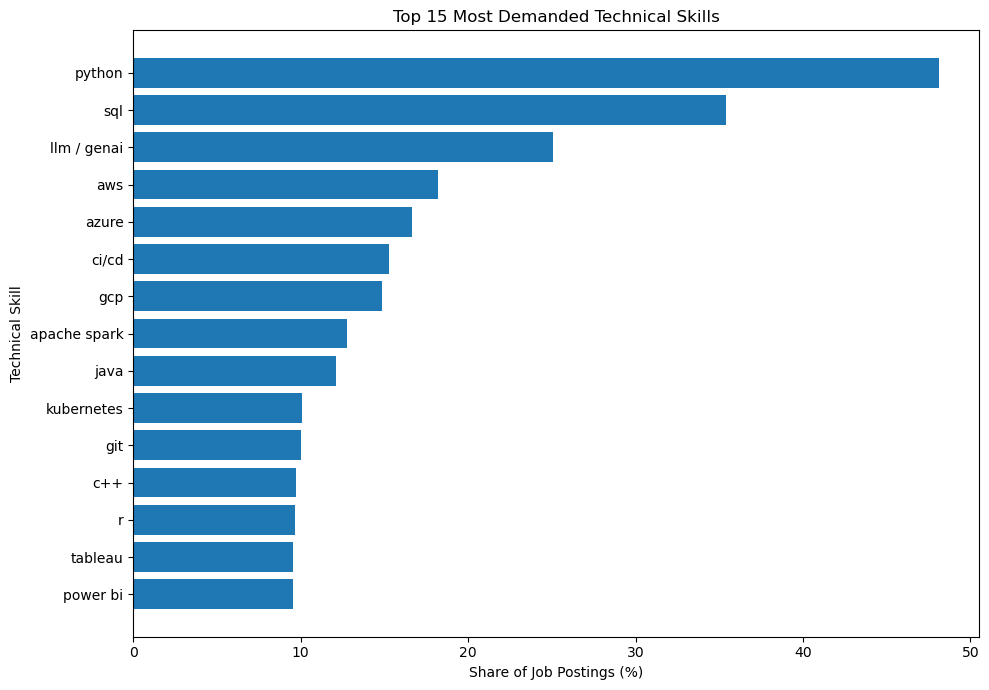

In [41]:
top_skills = (
    skill_frequency
    .head(15)
    .sort_values("demand_pct")
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_skills["skill"],
    top_skills["demand_pct"]
)

plt.xlabel("Share of Job Postings (%)")
plt.ylabel("Technical Skill")
plt.title("Top 15 Most Demanded Technical Skills")

plt.tight_layout()
plt.show()

#### <b>Compare skill demand by source</b>

In [42]:
# Because Muse and Himalayas have different patterns, we need to compare them separately

skill_source = (
    skills_exploded
    .merge(
        df[["job_uid", "source"]],
        on="job_uid",
        how="left"
    )
)

In [43]:
jobs_per_source = (
    df.groupby("source")["job_uid"]
    .nunique()
    .rename("total_jobs")
)

skill_by_source = (
    skill_source
    .groupby(["source", "skill"])
    .agg(job_count=("job_uid", "nunique"))
    .reset_index()
    .merge(jobs_per_source, on="source")
)

skill_by_source["demand_pct"] = (
    skill_by_source["job_count"]
    / skill_by_source["total_jobs"]
    * 100
)

In [44]:
# Top 10 per source

top_by_source = (
    skill_by_source
    .sort_values(
        ["source", "demand_pct"],
        ascending=[True, False]
    )
    .groupby("source")
    .head(10)
)

display(top_by_source)

,source,skill,job_count,total_jobs,demand_pct
32,himalayas,python,1789,3469,51.571058
41,himalayas,sql,1461,3469,42.115884
23,himalayas,llm / genai,1014,3469,29.230326
2,himalayas,aws,888,3469,25.598155
3,himalayas,azure,654,3469,18.852695
8,himalayas,ci/cd,565,3469,16.287114
12,himalayas,gcp,550,3469,15.854713
13,himalayas,git,468,3469,13.490920
31,himalayas,power bi,412,3469,11.876622
40,himalayas,snowflake,406,3469,11.703661


#### <b>Analyze Demand by Seniority</b>

In [45]:
# Merge skills with the same metadata 

skill_jobs = skills_exploded.merge(
    df[
        [
            "job_uid",
            "source",
            "level",
            "work_mode",
            "annual_salary"
        ]
    ],
    on="job_uid",
    how="left"
)

In [46]:
# Calculate skill demand within each level

jobs_per_level = (
    df.groupby("level")["job_uid"]
    .nunique()
    .rename("total_jobs")
)

skill_by_level = (
    skill_jobs
    .groupby(["level", "skill"])
    .agg(job_count=("job_uid", "nunique"))
    .reset_index()
    .merge(jobs_per_level, on="level")
)

skill_by_level["demand_pct"] = (
    skill_by_level["job_count"]
    / skill_by_level["total_jobs"]
    * 100
)

In [47]:
# Excluse intern from comparison because it contains very few jobs

skill_by_level_filtered = skill_by_level[
    skill_by_level["level"] != "Intern"
]

#### <b>Analyze demand by work mode</b>

In [48]:
jobs_per_mode = (
    df.groupby("work_mode")["job_uid"]
    .nunique()
    .rename("total_jobs")
)

skill_by_workmode = (
    skill_jobs
    .groupby(["work_mode", "skill"])
    .agg(job_count=("job_uid", "nunique"))
    .reset_index()
    .merge(jobs_per_mode, on="work_mode")
)

skill_by_workmode["demand_pct"] = (
    skill_by_workmode["job_count"]
    / skill_by_workmode["total_jobs"]
    * 100
)

Himalayas is a remote-only source, so work mode and data source are partially confounded. Work-mode comparisons should therefore be interpreted cautiously and checked against source-specific results.

#### <b>Build skill-pair statistics</b>

In [49]:
skills_by_job = (
    df.set_index("job_uid")["skills_clean"]
)

In [50]:
# Count combination

pair_counter = Counter()

for skills in skills_by_job:
    for pair in combinations(sorted(set(skills)), 2):
        pair_counter[pair] += 1

In [51]:
# DF conversion

skill_pairs = pd.DataFrame(
    [
        {
            "skill_1": pair[0],
            "skill_2": pair[1],
            "job_count": count
        }
        for pair, count in pair_counter.items()
    ]
)

skill_pairs = skill_pairs.sort_values(
    "job_count",
    ascending=False
)

#### <b>Add Jaccard similarity to normalize very common skills</b>

In [52]:
skill_counts = dict(
    skills_exploded
    .groupby("skill")["job_uid"]
    .nunique()
)

In [53]:
def compute_jaccard(row):
    a = skill_counts[row["skill_1"]]
    b = skill_counts[row["skill_2"]]
    intersection = row["job_count"]

    union = a + b - intersection

    return intersection / union

In [54]:
# Apply:

skill_pairs["jaccard"] = (
    skill_pairs.apply(
        compute_jaccard,
        axis=1
    )
)

display(
    skill_pairs
    .sort_values("job_count", ascending=False)
    .head(20)
)


,skill_1,skill_2,job_count,jaccard
68,python,sql,1649,0.403474
31,llm / genai,python,1054,0.265424
134,aws,python,796,0.211702
40,apache spark,python,742,0.215760
129,aws,azure,738,0.445383
136,azure,gcp,714,0.492754
142,gcp,python,693,0.190857
77,azure,python,681,0.180828
57,ci/cd,python,670,0.181966
131,aws,gcp,643,0.394721


### Skill Co-occurrence Patterns

The table above shows the most common pairs of technical skills found within the same job postings.

- **Python and SQL** form the most frequent pair, appearing together in 1,649 postings, suggesting that they are a foundational combination across many data and technical roles.
- Cloud technologies also show strong relationships. For example, **AWS–Azure** and **Azure–GCP** have relatively high Jaccard similarity scores, indicating that cloud platforms are often requested together rather than in isolation.
- **Python–LLM/GenAI** and **Python–Apache Spark** are also common combinations, reflecting the importance of Python across AI, machine learning, and data engineering roles.
- The Jaccard score helps distinguish genuinely strong relationships from pairs that simply involve very common skills. A higher value means that the two skills tend to occur together more consistently.

These co-occurrence relationships will later be used to build the skill network for the graph-analysis phase.
**Interpretation note:** `job_count` measures raw co-occurrence frequency, while `jaccard` measures normalized similarity. Therefore, a pair can have a high job count but only a moderate Jaccard score if both skills are individually very common.

In [55]:
# Also, inspect strongest normalized pairs:

display(
    skill_pairs[
        skill_pairs["job_count"] >= 20
    ]
    .sort_values("jaccard", ascending=False)
    .head(20)
)

,skill_1,skill_2,job_count,jaccard
287,numpy,pandas,82,0.515723
107,docker,kubernetes,385,0.497416
136,azure,gcp,714,0.492754
53,pytorch,tensorflow,322,0.475628
309,apache spark,scala,436,0.447179
129,aws,azure,738,0.445383
143,power bi,tableau,400,0.439078
184,pandas,scikit-learn,88,0.419048
68,python,sql,1649,0.403474
131,aws,gcp,643,0.394721


#### <b>Exports</b>

In [ ]:
skill_frequency.to_csv(
    "Datasets/skill_frequency_stats.csv",
    index=False
)

skill_by_source.to_csv(
    "Datasets/skill_by_source.csv",
    index=False
)

skill_by_level.to_csv(
    "Datasets/skill_by_seniority.csv",
    index=False
)

skill_by_workmode.to_csv(
    "Datasets/skill_by_workmode.csv",
    index=False
)

skill_pairs.to_csv(
    "Datasets/skill_pair_stats.csv",
    index=False
)

In [ ]:
# Export clean-job table

job_skills_clean = (
    df[["job_uid", "skills_clean"]]
    .explode("skills_clean")
    .dropna()
    .rename(columns={"skills_clean": "skill"})
)

job_skills_clean.to_csv(
    "Datasets/job_skills_clean.csv",
    index=False
)